# Week 2, core 1: Flexible models and the bias–variance trade-off

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cdds-uiuc/applied-ai-earth-sciences/blob/main/week02_regression_regularization/W02_core1_bias_variance.ipynb)

Week 1 ended with a warning: a degree-12 polynomial fitted the training points beautifully and the test points terribly. This notebook turns that warning into a principle. A model can be too simple to capture the pattern (**underfitting**, high **bias**) or so flexible that it captures the noise of one particular training set (**overfitting**, high **variance**), and the right amount of flexibility is the one that minimizes the error on data the model has not seen.

## What you will learn

- How training and test error change as a model becomes more flexible, and why they move in opposite directions past a point.
- What *bias* and *variance* mean, seen directly by fitting many models to many training sets.
- Why model flexibility must be chosen on data the model did not see, never on the training error.


In [1]:
# --- Setup: all imports, the seed, plot settings. The same block opens every notebook in this course. ---
import os
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed = 42                      # one seed for the whole notebook; re-set it before any cell you re-run
random.seed(seed)
np.random.seed(seed)

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 12
# Okabe–Ito: eight colorblind-safe colors as the default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#E69F00", "#56B4E9", "#009E73", "#F0E442",
                                                     "#0072B2", "#D55E00", "#CC79A7", "#000000"])


## A curved truth and a noisy training set

We again use synthetic data so that the truth is known. The rule below is a smooth curve with no particular physics behind it: think of it as some quantity that rises, peaks and falls along an environmental gradient. Forty noisy points form our training set; a much larger, separate set stands in for "all the data we will ever see".


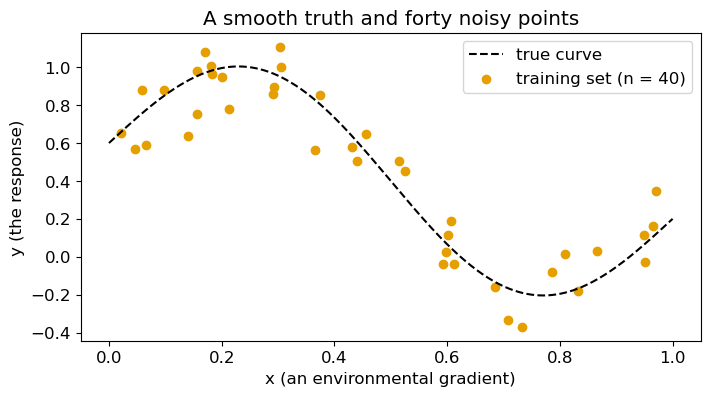

In [2]:
def true_curve(x: np.ndarray) -> np.ndarray:
    return 0.6 + 0.5 * np.sin(2 * np.pi * x) - 0.4 * x

n_train, n_test = 40, 400
noise_level = 0.15

x_train = np.sort(np.random.uniform(0, 1, n_train))                 # (n_train,)
y_train = true_curve(x_train) + np.random.normal(0, noise_level, n_train)
x_test = np.linspace(0, 1, n_test)                                   # (n_test,)
y_test = true_curve(x_test) + np.random.normal(0, noise_level, n_test)

fig, ax = plt.subplots()
ax.plot(x_test, true_curve(x_test), "k--", label="true curve")
ax.scatter(x_train, y_train, label=f"training set (n = {n_train})")
ax.set_xlabel("x (an environmental gradient)")
ax.set_ylabel("y (the response)")
ax.set_title("A smooth truth and forty noisy points")
ax.legend()
plt.show()


Forty points scattered around a smooth rise-and-fall curve; the scatter is the noise we added, with standard deviation 0.15.

## Flexibility as a dial: polynomial degree

A polynomial of degree 1 is a straight line; degree 2 can bend once; degree 15 can bend fourteen times. Degree is a dial for flexibility. For each degree we fit the polynomial to the training set and measure the root-mean-square error on the training points and on the test points.


lowest test RMSE at degree 5: 0.155  (the noise level is 0.15)


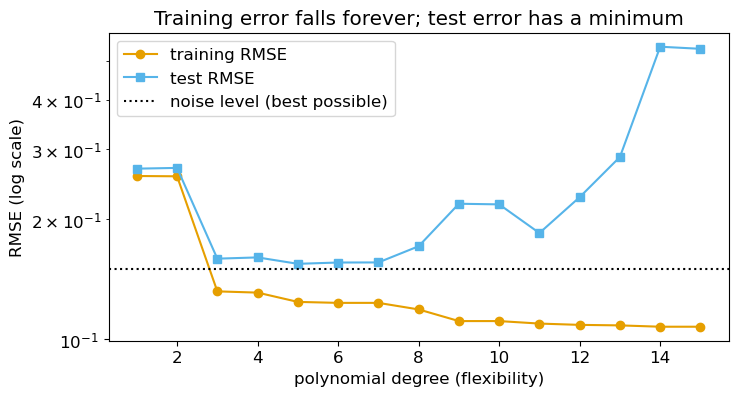

In [3]:
def rmse(y: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))

degrees = np.arange(1, 16)
train_rmse, test_rmse = [], []
for degree in degrees:
    poly = np.polynomial.Polynomial.fit(x_train, y_train, deg=degree)
    train_rmse.append(rmse(y_train, poly(x_train)))
    test_rmse.append(rmse(y_test, poly(x_test)))

best_degree = degrees[int(np.argmin(test_rmse))]
print(f"lowest test RMSE at degree {best_degree}: {min(test_rmse):.3f}  (the noise level is {noise_level})")

fig, ax = plt.subplots()
ax.plot(degrees, train_rmse, "o-", label="training RMSE")
ax.plot(degrees, test_rmse, "s-", label="test RMSE")
ax.axhline(noise_level, color="black", linestyle=":", label="noise level (best possible)")
ax.set_xlabel("polynomial degree (flexibility)")
ax.set_ylabel("RMSE (log scale)")
ax.set_yscale("log")
ax.set_title("Training error falls forever; test error has a minimum")
ax.legend()
plt.show()


The training error keeps falling as the degree grows, because a more flexible curve can always pass closer to the points it is fitted to. The test error falls at first (the line was too stiff), bottoms out around degree 3 to 5, and then climbs: the extra wiggles fit noise, not signal. The dotted line is the noise level, the best any model can do on average. (The vertical axis is logarithmic.)

Three fits make the picture concrete.


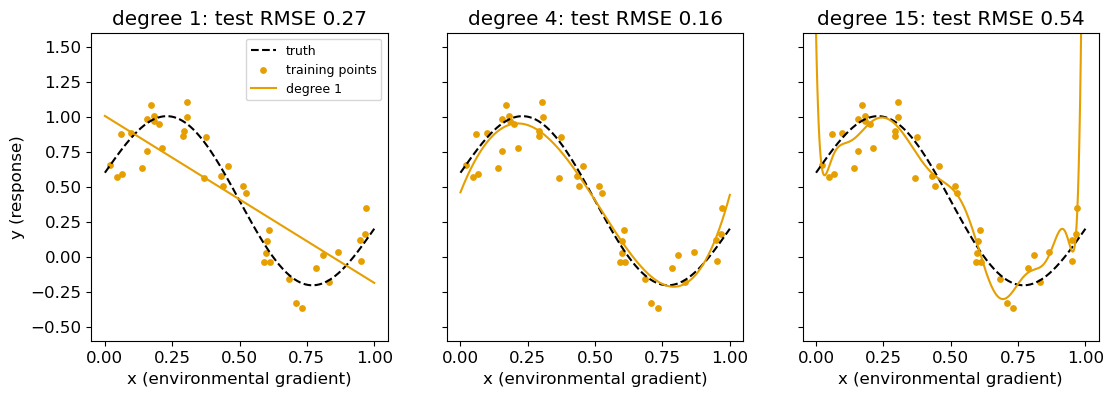

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, degree in zip(axes, [1, 4, 15]):
    poly = np.polynomial.Polynomial.fit(x_train, y_train, deg=degree)
    ax.plot(x_test, true_curve(x_test), "k--", label="truth")
    ax.scatter(x_train, y_train, s=15, label="training points")
    ax.plot(x_test, poly(x_test), label=f"degree {degree}")
    ax.set_ylim(-0.6, 1.6)
    ax.set_xlabel("x (environmental gradient)")
    ax.set_title(f"degree {degree}: test RMSE {rmse(y_test, poly(x_test)):.2f}")
axes[0].set_ylabel("y (response)")
axes[0].legend(fontsize=9)
plt.show()


Left: a straight line misses the curve entirely (underfitting). Middle: degree 4 follows the truth closely. Right: degree 15 threads the training points and swings wildly between them (overfitting).

> **Exercise.** Predict how the "lowest test RMSE" degree changes if the noise is doubled to `noise_level = 0.30`: higher, lower, or about the same? Write it down, then copy the data cell and the degree-sweep cell into the cell below, change the one number, and run (keep the seed line first so the only change is the noise). When you are done, re-run the original data cell and sweep cell above, so that the rest of the notebook uses the 40-point set again.


In [5]:
# Exercise 1: work here
np.random.seed(seed)


> **Exercise.** Now keep the noise at 0.15 but use `n_train = 200` training points. Predict first: does the right-hand side of the test-RMSE curve (the overfitting side) rise as steeply as before? Then run it, and afterwards re-run the original two cells as before.


In [6]:
# Exercise 2: work here
np.random.seed(seed)


> **Check your understanding.** Your colleague picks the polynomial degree that gives the lowest *training* error. Which degree will they always pick, and why is that a mistake?

## Bias and variance, seen directly

Why does the test error have a minimum? Imagine collecting a fresh training set of 40 points (same truth, new noise) and refitting. A stiff model gives nearly the same curve every time, but the curve is systematically wrong: that error is **bias**. A flexible model follows each training set's noise, so the fitted curve changes a lot from one training set to the next: that spread is **variance**. The test MSE is, roughly, bias² + variance + noise, and flexibility trades one for the other.

We can watch it happen by drawing 30 training sets and fitting degree 1 and degree 12 to each.


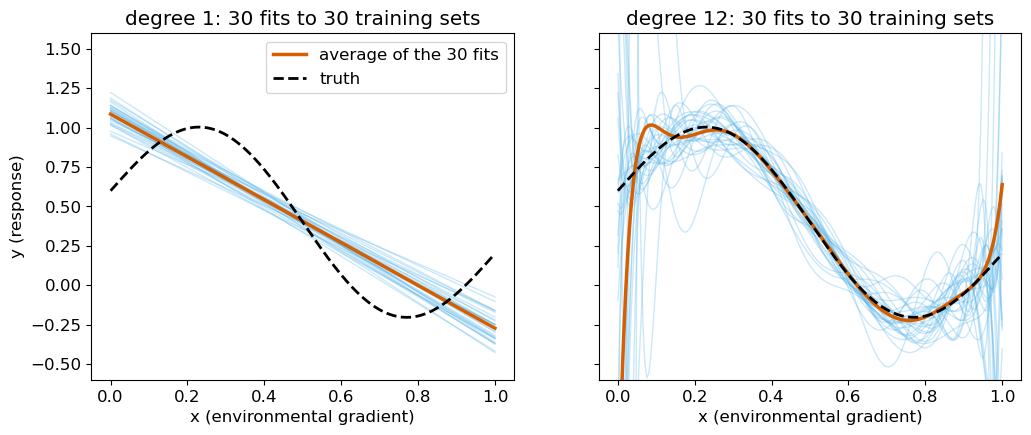

In [7]:
np.random.seed(seed)                    # re-set: this cell draws random training sets
n_repeats = 30
n_points = 40                           # the size of each training set, as above
x_grid = np.linspace(0, 1, 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, degree in zip(axes, [1, 12]):
    fits = np.zeros((n_repeats, len(x_grid)))                       # (n_repeats, n_grid)
    for r in range(n_repeats):
        x_sample = np.random.uniform(0, 1, n_points)
        y_sample = true_curve(x_sample) + np.random.normal(0, noise_level, n_points)
        poly = np.polynomial.Polynomial.fit(x_sample, y_sample, deg=degree)
        fits[r] = poly(x_grid)
        ax.plot(x_grid, fits[r], color="#56B4E9", alpha=0.3, linewidth=1)
    ax.plot(x_grid, fits.mean(axis=0), color="#D55E00", linewidth=2.5, label="average of the 30 fits")
    ax.plot(x_grid, true_curve(x_grid), "k--", linewidth=2, label="truth")
    ax.set_ylim(-0.6, 1.6)
    ax.set_xlabel("x (environmental gradient)")
    ax.set_title(f"degree {degree}: 30 fits to 30 training sets")
axes[0].set_ylabel("y (response)")
axes[0].legend()
plt.show()


Left, degree 1: the thirty light-blue lines sit almost on top of one another (low variance), but their average, in orange, is far from the dashed truth (high bias). Right, degree 12: the average tracks the truth well (low bias), but the individual fits fan out wildly between and beyond the data (high variance). A good model sits between these two pictures.

> **Check your understanding.** In which of the two panels would collecting *more* training data help the most, and what would it reduce: the bias or the variance?

## The deliberate failure: choosing flexibility on the training error

If you choose the degree by the training error, you always choose the most flexible model on offer, and you get the right-hand panel. Flexibility must be chosen on data the model did not see. In Week 1 that was a test set; this week's second core notebook and lab add a third split, a **validation set**, so that the test set stays untouched until the very end; Week 3 does it properly with cross-validation.


In [8]:
worst_choice = degrees[int(np.argmin(train_rmse))]
print(f"degree with the lowest training RMSE: {worst_choice}  (test RMSE {test_rmse[int(np.argmin(train_rmse))]:.3f})")
print(f"degree with the lowest test RMSE:     {best_degree}  (test RMSE {min(test_rmse):.3f})")


degree with the lowest training RMSE: 15  (test RMSE 0.537)
degree with the lowest test RMSE:     5  (test RMSE 0.155)


## Summary

- Flexibility is a dial. Training error always falls as it is turned up; test error falls, then rises.
- Bias is systematic error from a model too stiff to follow the truth; variance is sample-to-sample scatter from a model flexible enough to follow the noise.
- The flexibility of a model is chosen on data the model did not see, never on the training error.


## Exercise solutions

### Exercise 1 (noise doubled)

With the seed re-set, the noise pattern is the same as before, only doubled, so the whole curve nearly doubles: for this training set the best degree stays at 5 and the minimum test RMSE rises to 0.31, the new noise level. Across many different training sets the best degree drifts down only mildly with more noise; what is robust is that the minimum test RMSE tracks the noise level and that the overfitting side gets steeper.

### Exercise 2 (200 training points)

With five times more data the overfitting side of the curve flattens: high-degree polynomials have enough points to be pinned down, so their test RMSE stays near the floor. More data reduces variance, which is why large datasets tolerate flexible models. (At degree 15 the test RMSE drops from 0.54 with 40 points to 0.19 with 200.)

### Check-your-understanding answers

- *Choosing by training error.* They always pick the most flexible model on offer (degree 15), because training error never rises with flexibility; that model has the worst test error of the sweep.
- *Where more data helps.* The right-hand, degree-12 panel: more data pins down the flexible fits and reduces their spread, the variance. In the left panel the lines already agree; their shared error is bias, and no amount of data fixes a model that cannot bend.
